# Community Detection - Bluesky Financial Ticker Network

1. Graph creation
2. Community Discovery algorithm selection
3. Clustering evaluation with fitness functions
4. Clustering comparison
5. Qualitative validation with node attributes



In [ ]:

%pip install cdlib python-louvain networkx pandas numpy matplotlib -q


Note: you may need to restart the kernel to use updated packages.


In [18]:
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')


<a id='graph'></a>
## Graph object creation



In [19]:
CSV_PATH = "bluesky_large_edges_unweighted_10000 (1).csv"
METADATA_PATH = "ticker_metadata.csv"


def read_net(filename):
    g = nx.Graph()
    with open(filename) as f:
        f.readline()
        for l in f:
            l = l.rstrip().split(",")
            if len(l) >= 2:
                g.add_edge(l[0], l[1])
    return g


g = read_net(CSV_PATH)

print("Nodes:", g.number_of_nodes())
print("Edges:", g.number_of_edges())
print("Density:", nx.density(g))
print("Self-loops:", nx.number_of_selfloops(g))


Nodes: 6243
Edges: 462904
Density: 0.02375766914695821
Self-loops: 0


In [20]:
components = sorted(nx.connected_components(g), key=len, reverse=True)

print("Connected components:", len(components))
print("Largest component size:", len(components[0]))
print("Largest component coverage:", len(components[0]) / g.number_of_nodes())


Connected components: 16
Largest component size: 6211
Largest component coverage: 0.9948742591702707


<a id='model'></a>
## Community Discovery algorithm selection

In [21]:
from cdlib import algorithms

lp_coms = algorithms.label_propagation(g)
louvain_coms = algorithms.louvain(g)
greedy_coms = algorithms.greedy_modularity(g)

clusterings = [louvain_coms, lp_coms, greedy_coms]


In [22]:
for coms in clusterings:
    print("Method:", coms.method_name)
    print("Communities:", len(coms.communities))
    print("Node coverage:", coms.node_coverage)
    print("Overlapping:", coms.overlap)
    print()


Method: Louvain
Communities: 26
Node coverage: 1.0
Overlapping: False

Method: Label Propagation
Communities: 47
Node coverage: 1.0
Overlapping: False

Method: Greedy Modularity
Communities: 49
Node coverage: 1.0
Overlapping: False



In [23]:
# Inspect one clustering object, as in the class notebook.
louvain_coms.method_name, louvain_coms.method_parameters, louvain_coms.node_coverage


('Louvain', {'weight': 'weight', 'resolution': 1.0, 'randomize': None}, 1.0)

<a id='fitness'></a>
## Clustering Evaluation - Fitness functions

The following measures summarize the quality of each partition. Higher modularity and internal density are usually better; lower conductance is usually better.


In [24]:
from cdlib import evaluation


def score(result):
    if hasattr(result, "score"):
        return result.score
    return result


fitness_rows = []

for coms in clusterings:
    fitness_rows.append({
        "method": coms.method_name,
        "communities": len(coms.communities),
        "coverage": coms.node_coverage,
        "modularity": score(evaluation.newman_girvan_modularity(g, coms)),
        "avg_internal_degree": score(evaluation.average_internal_degree(g, coms)),
        "internal_edge_density": score(evaluation.internal_edge_density(g, coms)),
        "conductance": score(evaluation.conductance(g, coms)),
    })

fitness = pd.DataFrame(fitness_rows)
fitness.sort_values("modularity", ascending=False)


,method,communities,coverage,modularity,avg_internal_degree,internal_edge_density,conductance
0,Louvain,26,1.0,0.222605,14.966623,0.721566,0.216054
2,Greedy Modularity,49,1.0,0.205841,6.653730,0.797427,0.369768
1,Label Propagation,47,1.0,0.000445,4.640389,0.930414,0.259511


In [25]:
# Community-wise values for one algorithm.
louvain_coms.average_internal_degree(summary=False)[:10]


[98.72082018927445,
 165.54517611026034,
 19.914473684210527,
 31.8407960199005,
 20.20246913580247,
 14.308457711442786,
 16.466666666666665,
 1.8,
 2.0,
 2.0]

<a id='comparison'></a>
## Clustering Evaluation - Comparison

When multiple clusterings are computed on the same graph, we compare their resemblance with NMI and AMI.


In [26]:
comparison_rows = []

for i, first in enumerate(clusterings):
    for second in clusterings[i + 1:]:
        comparison_rows.append({
            "first": first.method_name,
            "second": second.method_name,
            "NMI": score(evaluation.normalized_mutual_information(first, second)),
            "AMI": score(evaluation.adjusted_mutual_information(first, second)),
        })

pd.DataFrame(comparison_rows)


,first,second,NMI,AMI
0,Louvain,Label Propagation,0.088211,0.069866
1,Louvain,Greedy Modularity,0.433483,0.423793
2,Label Propagation,Greedy Modularity,0.182211,0.167415


<a id='visualization'></a>
## Community/Statistics visualization

The complete graph is too dense to visualize clearly node-by-node. We therefore use the same CDlib visualization functions shown in class, but we draw node-level clusters on a readable top-degree subgraph and use aggregate community plots for the full graph.

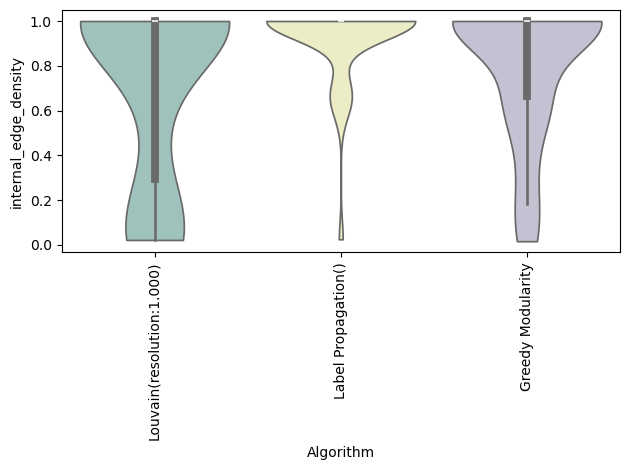

In [27]:
from cdlib import viz

viz.plot_com_stat(clusterings, evaluation.internal_edge_density)
plt.show()


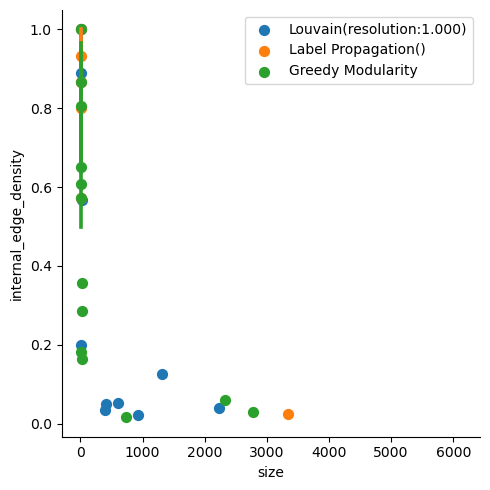

In [28]:
viz.plot_com_properties_relation(clusterings, evaluation.size, evaluation.internal_edge_density)
plt.show()


### Community size distribution

First, we inspect how many nodes are assigned to each community.

In [29]:
def community_size_dataframe(clusterings):
    rows = []
    for coms in clusterings:
        for i, community in enumerate(coms.communities):
            rows.append({
                "method": coms.method_name,
                "community_id": i,
                "size": len(community),
            })
    return pd.DataFrame(rows)


size_df = community_size_dataframe(clusterings)
size_df.sort_values(["method", "size"], ascending=[True, False]).head(15)

,method,community_id,size
73,Greedy Modularity,0,3219
74,Greedy Modularity,1,2277
75,Greedy Modularity,2,555
76,Greedy Modularity,3,21
77,Greedy Modularity,4,20
78,Greedy Modularity,5,17
79,Greedy Modularity,6,11
80,Greedy Modularity,7,8
81,Greedy Modularity,8,7
82,Greedy Modularity,9,5


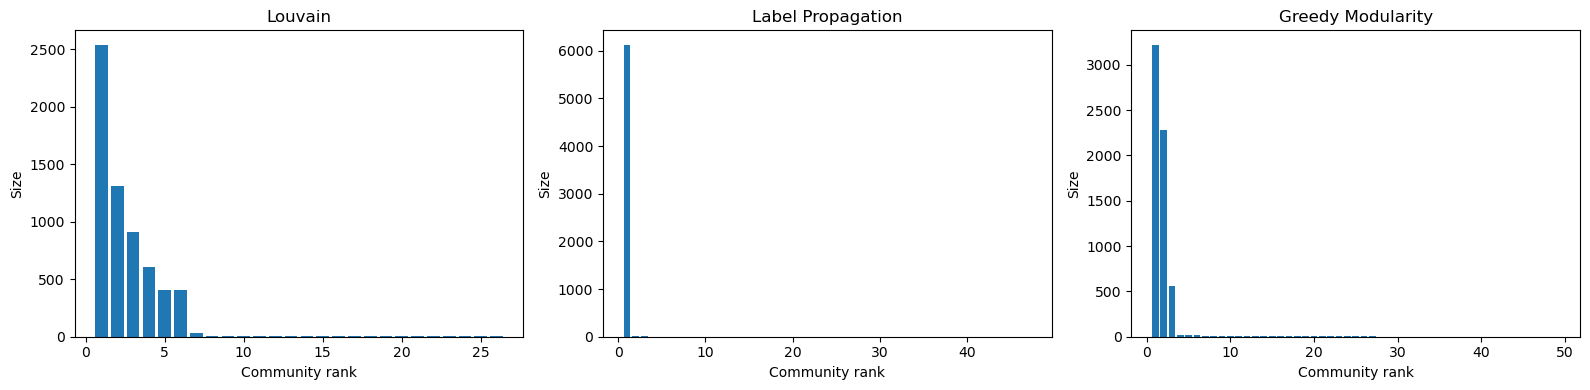

In [30]:
fig, axes = plt.subplots(1, len(clusterings), figsize=(16, 4))

for ax, coms in zip(axes, clusterings):
    sizes = sorted([len(c) for c in coms.communities], reverse=True)
    ax.bar(range(1, len(sizes) + 1), sizes)
    ax.set_title(coms.method_name)
    ax.set_xlabel("Community rank")
    ax.set_ylabel("Size")

plt.tight_layout()
plt.show()

### Network clusters on a readable sample

As in the class notebook, we color nodes according to their detected community. For readability, the plot uses the 250 highest-degree nodes from the original graph.

In [31]:
from cdlib import NodeClustering


def clustering_on_subgraph(coms, subgraph):
    sub_nodes = set(subgraph.nodes())
    sub_communities = []

    for community in coms.communities:
        nodes = list(sub_nodes.intersection(community))
        if len(nodes) > 0:
            sub_communities.append(nodes)

    return NodeClustering(
        communities=sub_communities,
        graph=subgraph,
        method_name=coms.method_name,
        method_parameters=coms.method_parameters,
        overlap=coms.overlap,
    )


TOP_NODES = 250
sample_nodes = [node for node, degree in sorted(g.degree(), key=lambda x: x[1], reverse=True)[:TOP_NODES]]
g_viz = g.subgraph(sample_nodes).copy()
louvain_viz = clustering_on_subgraph(louvain_coms, g_viz)

print("Visualization subgraph nodes:", g_viz.number_of_nodes())
print("Visualization subgraph edges:", g_viz.number_of_edges())

Visualization subgraph nodes: 250
Visualization subgraph edges: 25510


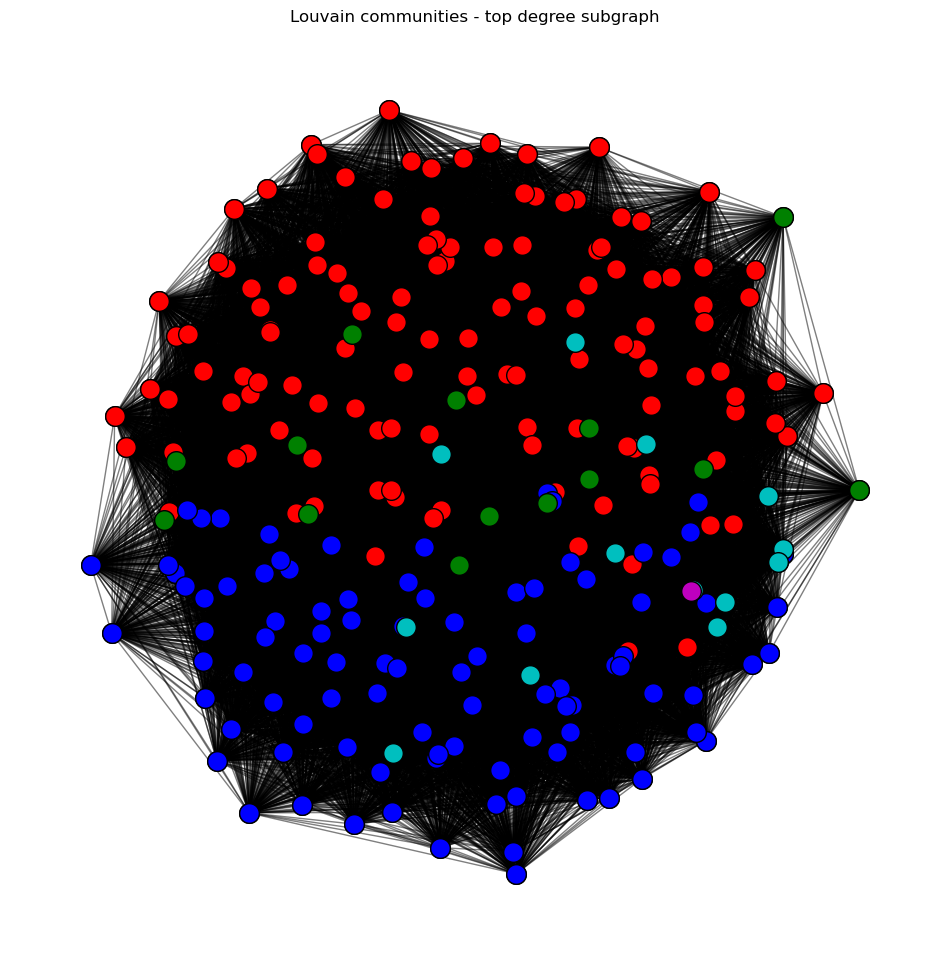

In [32]:
pos = nx.spring_layout(g_viz, seed=42)

viz.plot_network_clusters(
    g_viz,
    louvain_viz,
    pos,
    figsize=(12, 12),
    plot_labels=False,
)
plt.title("Louvain communities - top degree subgraph")
plt.show()

### Community graph

The community graph collapses each community into a meta-node, making the global structure easier to read.

Louvain


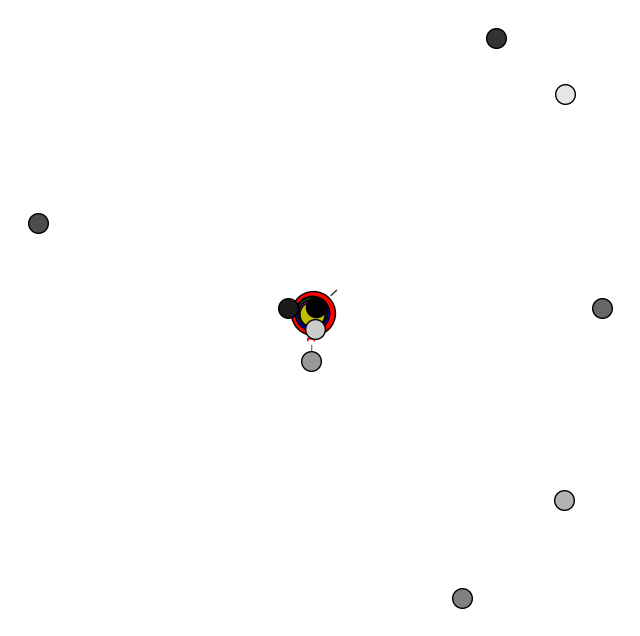

Label Propagation


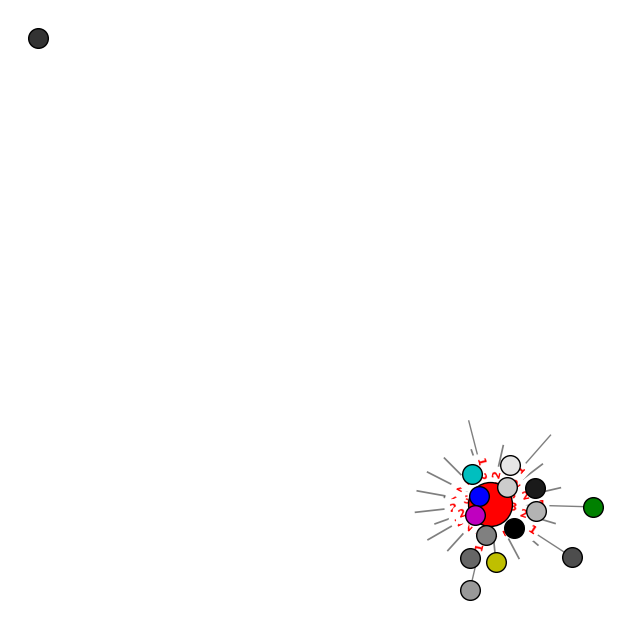

Greedy Modularity


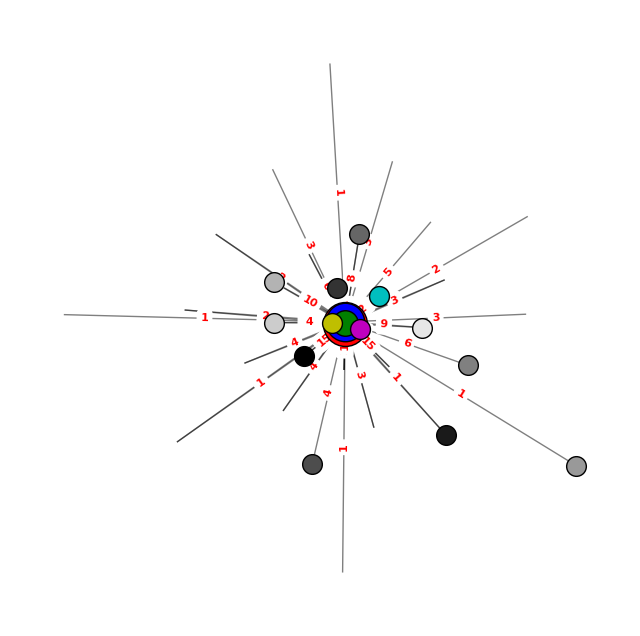

In [33]:
for coms in clusterings:
    print(coms.method_name)
    viz.plot_community_graph(g, coms, figsize=(8, 8))
    plt.show()

### Similarity matrix

This plot summarizes how similar the partitions are to each other.

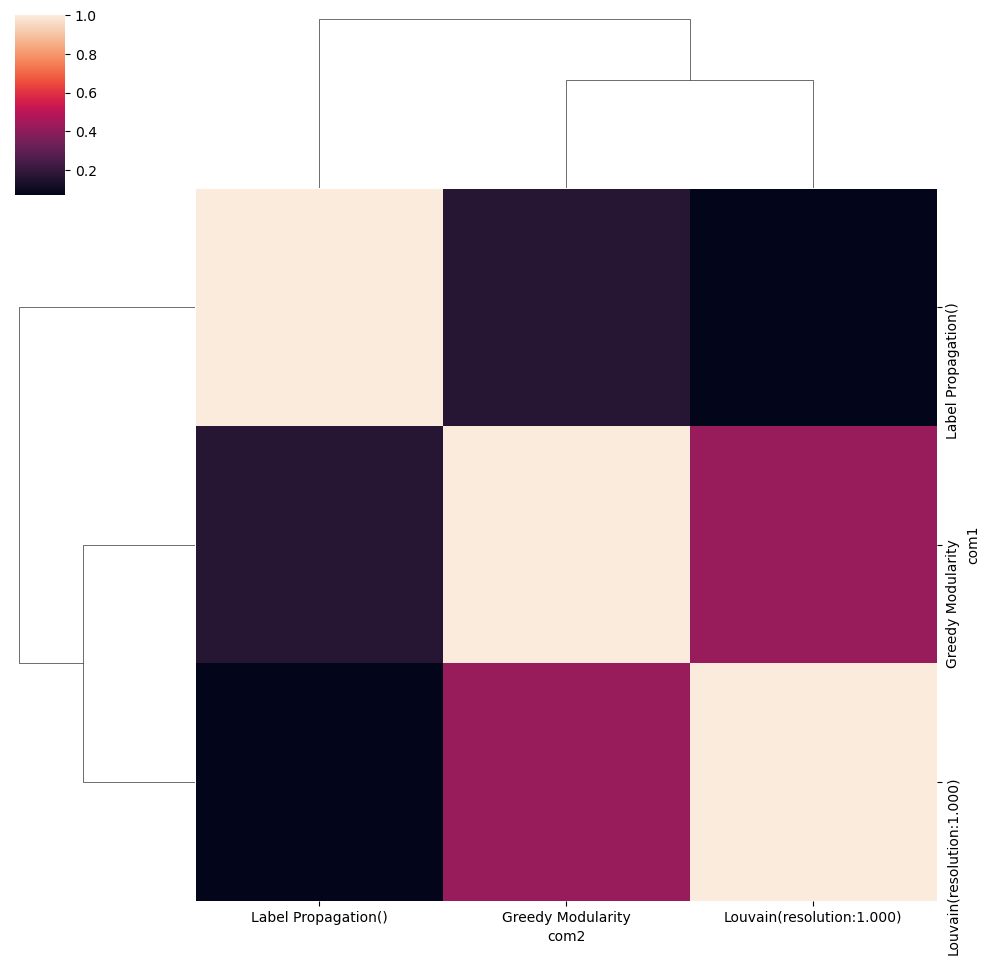

In [34]:
viz.plot_sim_matrix(clusterings, evaluation.adjusted_mutual_information)
plt.show()

<a id='qualitative'></a>
## Qualitative evaluation with ticker sectors

The metadata file gives us a sector for many tickers. We use it as an external attribute to check whether communities are semantically coherent.


In [35]:
metadata = pd.read_csv(METADATA_PATH)
metadata["sector"] = metadata["sector"].fillna("Unknown")
node_to_sector = dict(zip(metadata["ticker"], metadata["sector"]))

metadata.head()


,ticker,company,sector,industry,country,exchange
0,A,"Agilent Technologies, Inc.",Healthcare,Diagnostics & Research,United States,NYQ
1,AA,Alcoa Corporation,Basic Materials,Aluminum,United States,NYQ
2,AACOU,Abony Acquisition Corp. I,Financial Services,Shell Companies,United States,NGM
3,AADX,"Applied Aerospace & Defense, Inc.",Industrials,Aerospace & Defense,United States,NYQ
4,AAL,American Airlines Group Inc.,Industrials,Airlines,United States,NMS


### Sector composition of the largest communities

This plot helps connect the detected structure with the financial meaning of the nodes.

In [36]:
def community_sector_matrix(coms, node_to_sector, n_communities=10, n_sectors=8):
    communities = sorted(coms.communities, key=len, reverse=True)[:n_communities]
    rows = []

    for i, community in enumerate(communities):
        sectors = [node_to_sector.get(node, "Unknown") for node in community]
        counts = Counter(sectors)
        total = sum(counts.values())

        row = {"community": f"C{i} ({len(community)})"}
        for sector, count in counts.most_common(n_sectors):
            row[sector] = count / total
        rows.append(row)

    return pd.DataFrame(rows).fillna(0).set_index("community")


sector_matrix = community_sector_matrix(louvain_coms, node_to_sector)
sector_matrix

,Healthcare,Technology,Industrials,Financial Services,Consumer Cyclical,Unknown,Basic Materials,Communication Services,Real Estate,Consumer Defensive,Energy
community,,,,,,,,,,,
C0 (2536),0.290221,0.151025,0.106861,0.100158,0.076104,0.056782,0.053628,0.046530,0.000000,0.000000,0.000000
C1 (1306),0.089587,0.127871,0.133231,0.201378,0.103369,0.053599,0.000000,0.000000,0.062021,0.050536,0.000000
C2 (912),0.026316,0.024123,0.029605,0.110746,0.026316,0.731360,0.010965,0.009868,0.000000,0.000000,0.000000
C3 (603),0.107794,0.174129,0.155887,0.129353,0.177446,0.000000,0.039801,0.000000,0.000000,0.053068,0.038143
C4 (405),0.061728,0.069136,0.113580,0.125926,0.049383,0.395062,0.000000,0.000000,0.044444,0.000000,0.074074
C5 (402),0.134328,0.089552,0.104478,0.273632,0.059701,0.074627,0.000000,0.062189,0.089552,0.000000,0.000000
C6 (30),0.000000,0.033333,0.033333,0.000000,0.000000,0.933333,0.000000,0.000000,0.000000,0.000000,0.000000
C7 (10),0.000000,0.000000,0.000000,0.600000,0.000000,0.300000,0.000000,0.000000,0.000000,0.100000,0.000000
C8 (3),0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000


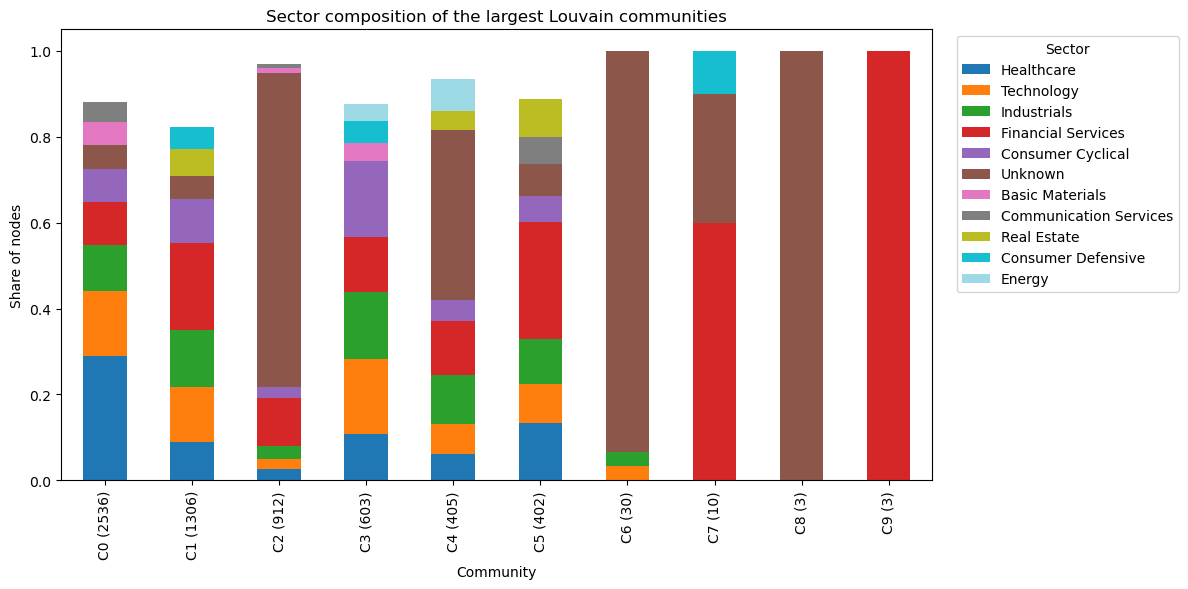

In [37]:
ax = sector_matrix.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
)

ax.set_title("Sector composition of the largest Louvain communities")
ax.set_xlabel("Community")
ax.set_ylabel("Share of nodes")
ax.legend(title="Sector", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [38]:
def community_purity(coms, node_to_attribute):
    purities = []

    for c in coms.communities:
        attributes = []
        for node in c:
            attributes.append(node_to_attribute.get(node, "Unknown"))

        cnt = Counter(attributes)
        purity = max(cnt.values()) / sum(cnt.values())
        purities.append(purity)

    return purities


In [39]:
purity_rows = []

for coms in clusterings:
    purities = community_purity(coms, node_to_sector)
    purity_rows.append({
        "method": coms.method_name,
        "mean_sector_purity": np.mean(purities),
        "std_sector_purity": np.std(purities),
        "min_sector_purity": np.min(purities),
        "max_sector_purity": np.max(purities),
    })

pd.DataFrame(purity_rows).sort_values("mean_sector_purity", ascending=False)


,method,mean_sector_purity,std_sector_purity,min_sector_purity,max_sector_purity
1,Label Propagation,0.958063,0.154620,0.171811,1.0
2,Greedy Modularity,0.845791,0.247230,0.235294,1.0
0,Louvain,0.811632,0.295856,0.177446,1.0


In [40]:
def describe_largest_communities(coms, node_to_attribute, n=10):
    rows = []
    communities = sorted(coms.communities, key=len, reverse=True)[:n]

    for i, c in enumerate(communities):
        attributes = [node_to_attribute.get(node, "Unknown") for node in c]
        cnt = Counter(attributes)
        main_attribute, main_count = cnt.most_common(1)[0]

        rows.append({
            "community_id": i,
            "size": len(c),
            "main_sector": main_attribute,
            "main_sector_share": main_count / len(c),
            "example_tickers": ", ".join(sorted(c)[:10]),
        })

    return pd.DataFrame(rows)


describe_largest_communities(louvain_coms, node_to_sector, n=10)


,community_id,size,main_sector,main_sector_share,example_tickers
0,0,2536,Healthcare,0.290221,"AAOI, AAOX, AAPG, AARD, AAUC, ABAT, ABCL, ABEO..."
1,1,1306,Financial Services,0.201378,"A, AA, AAL, AAP, AAPL, ABBV, ABG, ABI, ABLD, ABNB"
2,2,912,Unknown,0.731360,"ABEV, ACEL, ACONW, ACWI, ACWX, AETH, AFBI, AFC..."
3,3,603,Consumer Cyclical,0.177446,"AAME, AAON, AAXJ, ABM, ABVC, ABX, ACCO, ACCS, ..."
4,4,405,Unknown,0.395062,"AB, ACA, ACDC, ACH, ACM, ACU, ADEA, ADX, AEIS,..."
5,5,402,Financial Services,0.273632,"AADX, AAMI, AAT, ABCB, ACFN, AD, ADCT, AEC, AG..."
6,6,30,Unknown,0.933333,"AAPD, AMDD, AMZD, AVS, BITI, BMNZ, CONI, CRCD,..."
7,7,10,Financial Services,0.600000,"AACOU, AGCC, CMIIU, ECCU, HCAC, KKRT, LPCVU, M..."
8,8,3,Unknown,1.000000,"ICOI, IMRA, IMST"
9,9,3,Financial Services,1.000000,"ASGI, UTF, UTG"


## Notes for the report

Use the tables above to discuss:

- which algorithm gives the highest modularity and internal density;
- whether the algorithms agree with each other according to NMI/AMI;
- whether communities correspond to financial sectors or mix different sectors;
- examples from the largest communities, using the ticker names and sectors.
